## Семинар 7: Рекуррентные нейросети (LSTM, внимание). Предобработка текста.




На этом семинаре мы познакомимся с понятием реккурентных нейронных сетей, их реализацией в PyTorch. Научимся предобрабатывать текстовые данные и посмотрим, как корректная предобработка влияет на результат предсказания. А также обучим реккурентную нейронную сеть определять токсичность комментариев.


--------

In [3]:
!pip install pymorphy3

In [4]:
import os
import pandas as pd
from collections import defaultdict
import time

import re
import pymorphy3
import nltk
from nltk.corpus import stopwords

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

### 1. Особенности обработки текста

Обработка текста в машинном обучении, также известная как обработка естественного языка (NLP), включает в себя несколько ключевых особенностей и этапов:

1. <font color='plum'>**Предобработка текста:**</font>
   - Токенизация: Разделение текста на отдельные слова или токены.
   - Стемминг и лемматизация: Приведение слов к их базовой или корневой форме.
   - Удаление стоп-слов: исключение часто встречающихся слов, которые не несут значимой информации (например, "и", "в", "на").
   - Нормализация текста: Приведение текста к единому виду, например, перевод всех символов в нижний регистр.

2. <font color='plum'>**Представление текста:**</font>
   - Мешок слов (Bag of Words): Представление текста в виде вектора, где учитывается частота каждого слова.
   - TF-IDF (Term Frequency-Inverse Document Frequency): Взвешенное представление, учитывающее важность слова в документе относительно всего корпуса.
   - Вордэмбеддинги (Word Embeddings): Плотные векторные представления слов, такие как Word2Vec, GloVe или FastText, которые захватывают семантические отношения между словами.
   - Контекстуальные эмбеддинги: Использование моделей, таких как BERT или GPT, которые учитывают контекст слова в предложении.

3. <font color='plum'>**Моделирование**</font> (Классификация текста, Извлечение информации, Генерация текста).

4. <font color='plum'>**Оценка и интерпретация.**</font>

На этом семинаре мы подробно разберем первый этап и частично затронем 2 и 3 этапы.

Давайте воспользуемся примером и вспомним, как в python организована предобработка текста.




In [5]:
example = "Я очень люблю курс по Deep Learning в 2025 году!!! :)))))"

#### Нормализация текста

Начнем с <font color='CornflowerBlue'>**нормализации**</font> текста: под ней подразумевается приведение текста к единому виду, например, перевод всех символов в нижний регистр и удаление пунктуации.

Приведение текста в нижний регистр выпоняется достаточно просто: необходимо воспользоваться встроенным методом `str.lower()`:


In [6]:
example = example.lower()
example

'я очень люблю курс по deep learning в 2025 году!!! :)))))'

Можно также привести текст в uppercase:

In [7]:
example.upper()

'Я ОЧЕНЬ ЛЮБЛЮ КУРС ПО DEEP LEARNING В 2025 ГОДУ!!! :)))))'

Удаление или преобразование символов выполняется чуть сложнее. Для этого необходимо воспользоваться библиотекой `re` - она предоставляет мощные инструменты для работы с регулярными выражениями, которые позволяют выполнять сложные операции поиска и замены в строках. Давайте коротко перечислим функции из нее, которые могут вам понадобиться.

1. `re.search()`:
   - Ищет первое совпадение с регулярным выражением в строке. Возвращает объект Match, если совпадение найдено, или None, если нет.

In [8]:
print(example)
print(f"Can I found 'dl' in example? {re.search('dl', example)}")
print(f"Can I found 'deep' in example? {re.search('deep', example)}")

я очень люблю курс по deep learning в 2025 году!!! :)))))
Can I found 'dl' in example? None
Can I found 'deep' in example? <re.Match object; span=(22, 26), match='deep'>


При отсутствии паттерна в строке `re.search` возвращает `None`. В противном случае возвращается объект `re.Match`, к которому можно обращаться:

In [ ]:
ob = re.search('deep', example)
ob[0], ob.span()

('deep', (22, 26))

In [ ]:
ob = re.search('глубокое', example)
print(ob)

None


2. `re.findall()`:
   - Возвращает список всех непересекающихся совпадений с регулярным выражением в строке. Если совпадений нет, возвращает пустой список.

In [9]:
print(example)
print(f"Can I found 'dl' in example? {re.findall('dl', example)}")
print(f"Can I found 'лю' in example? {re.findall('лю', example)}")

я очень люблю курс по deep learning в 2025 году!!! :)))))
Can I found 'dl' in example? []
Can I found 'лю' in example? ['лю', 'лю']


3. `re.split()`:
   - Разделяет строку по совпадениям с регулярным выражением. Возвращает список строк.

In [10]:
print(example)
re.split('!', example)

я очень люблю курс по deep learning в 2025 году!!! :)))))


['я очень люблю курс по deep learning в 2025 году', '', '', ' :)))))']

4. `re.sub()`:
   - Заменяет все совпадения с регулярным выражением в строке на заданную замену. Возвращает новую строку с заменами.

Напомним основные концепции и элементы регулярных выражений:

1. Базовые символы:
   - Литералы: Обычные символы, которые соответствуют самим себе (например, `a, b, 1`).
   - Точка (`.`): Соответствует любому одиночному символу, кроме символа новой строки.

2. Квантификаторы:
   - `*`: Соответствует 0 или более повторениям предыдущего элемента.
   - `+`: Соответствует 1 или более повторениям предыдущего элемента.
   - `?`: Соответствует 0 или 1 повторению предыдущего элемента.
   - `{n}`: Соответствует ровно n повторениям предыдущего элемента.
   - `{n,}`: Соответствует n или более повторениям.
   - `{n,m}`: Соответствует от n до m повторений.

3. Группировка и альтернативы:
   - Круглые скобки (`()`): Используются для группировки элементов и создания подвыражений.
   - Вертикальная черта (`|`): Оператор "или", который позволяет выбирать между альтернативами (например, `a|b` соответствует a или b).

4. Множества символов:
   - Квадратные скобки (`[]`): Определяют набор символов, любой из которых может соответствовать (например, `[abc]` соответствует a, b или c).
   - Диапазоны: Можно задавать диапазоны символов (например, `[a-z]` соответствует любой строчной букве).
   - Отрицание: Символ `^` в начале множества символов отрицает его (например, `[^abc]` соответствует любому символу, кроме a, b или c).

5. Якоря:
   - `^`: Соответствует началу строки.
   - `$`: Соответствует концу строки.

6. Специальные последовательности:
   - `\d`: Соответствует любой цифре (эквивалентно `[0-9]`).
   - `\D`: Соответствует любому символу, который не является цифрой.
   - `\w`: Соответствует любой букве, цифре или символу подчеркивания (эквивалентно `[a-zA-Z0-9_]`).
   - `\W`: Соответствует любому символу, который не является буквой, цифрой или символом подчеркивания.
   - `\s`: Соответствует любому пробельному символу (включая пробел, табуляцию и новую строку).
   - `\S`: Соответствует любому символу, который не является пробельным.

In [11]:
example = "Я очень люблю курс по Deep Learning в 2024 году!!! :)))))"
print(example)
print('----------------')
print(re.sub(r'\d', '', example)) # delete numbers
print(re.sub(r'\D', '', example)) # delete non numbers
print(re.sub(r'\w', '', example)) # delete [a-zA-Z0-9_]

Я очень люблю курс по Deep Learning в 2024 году!!! :)))))
----------------
Я очень люблю курс по Deep Learning в  году!!! :)))))
2024
         !!! :)))))


In [20]:
example = "Я очень люблю курс по Deep Learning в 2024 году !!! :)))))"
print(example)
print(re.sub(r'\d{5}', '', example)) # delete numbers

Я очень люблю курс по Deep Learning в 2024 году !!! :)))))
Я очень люблю курс по Deep Learning в 2024 году !!! :)))))


#### Токенизация

В современных моделях зачастую нормализации оказывается достаточно для получения высокого качества предсказания.

Теперь перейдем к <font color='CornflowerBlue'>**токенизации**</font> - это процесс разделения текста на отдельные слова или токены. Разбить текст на токены можно как с помощью простых методов, таких как str.split(), так и воспользоваться более сложными токенизаторами, например, из библиотеки NLTK или SpaCy.

In [21]:
word_list = example.split()
print(word_list)

clever_word_list = re.split(' ', example)
print(clever_word_list)

['Я', 'очень', 'люблю', 'курс', 'по', 'Deep', 'Learning', 'в', '2024', 'году', '!!!', ':)))))']
['Я', 'очень', 'люблю', 'курс', 'по', 'Deep', 'Learning', 'в', '2024', 'году', '!!!', ':)))))']


#### Стемминг и лемматизация

После того, как мы разбили текст на токены, можно перейти к <font color='CornflowerBlue'>**стеммингу**</font> или <font color='CornflowerBlue'>**лемматизации**</font> - приведению слов к их базовой или корневой форме. Это можно сделать с помощью библиотек NLTK или SpaCy. Для лемматизации текста на русском языке можно использовать библиотеку pymorphy2.

In [22]:
# Инициализация анализатора
morph = pymorphy3.MorphAnalyzer()

# Лемматизация слов
lemmatized_words = [morph.parse(word)[0].normal_form for word in word_list]
print(lemmatized_words)
# Объединение слов обратно в строку
lemmatized_text = ' '.join(lemmatized_words)

print(lemmatized_text)

['я', 'очень', 'любить', 'курс', 'по', 'deep', 'learning', 'в', '2024', 'год', '!!!', ':)))))']
я очень любить курс по deep learning в 2024 год !!! :)))))


Наконец, завершающий этап: **удаление стоп-слов**, т.е. исключение часто встречающихся слов, которые не несут значимой информации. Для этого можно использовать списки стоп-слов из библиотек NLTK или SpaCy.

In [15]:
# Загрузка стоп-слов
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [16]:
example

'Я очень люблю курс по Deep Learning в 2024 году!!! :)))))'

In [18]:
# Получение списка стоп-слов для русского языка
stop_words = set(stopwords.words('russian'))
len(stop_words)

# Удаление стоп-слов
filtered_words = [word for word in lemmatized_words if word not in stop_words]

# Объединение слов обратно в строку
filtered_text = ' '.join(filtered_words)
print(filtered_text)

очень любить курс deep learning 2024 году!!! :)))))


In [19]:
stop_words

{'а',
 'без',
 'более',
 'больше',
 'будет',
 'будто',
 'бы',
 'был',
 'была',
 'были',
 'было',
 'быть',
 'в',
 'вам',
 'вас',
 'вдруг',
 'ведь',
 'во',
 'вот',
 'впрочем',
 'все',
 'всегда',
 'всего',
 'всех',
 'всю',
 'вы',
 'где',
 'да',
 'даже',
 'два',
 'для',
 'до',
 'другой',
 'его',
 'ее',
 'ей',
 'ему',
 'если',
 'есть',
 'еще',
 'ж',
 'же',
 'за',
 'зачем',
 'здесь',
 'и',
 'из',
 'или',
 'им',
 'иногда',
 'их',
 'к',
 'как',
 'какая',
 'какой',
 'когда',
 'конечно',
 'кто',
 'куда',
 'ли',
 'лучше',
 'между',
 'меня',
 'мне',
 'много',
 'может',
 'можно',
 'мой',
 'моя',
 'мы',
 'на',
 'над',
 'надо',
 'наконец',
 'нас',
 'не',
 'него',
 'нее',
 'ней',
 'нельзя',
 'нет',
 'ни',
 'нибудь',
 'никогда',
 'ним',
 'них',
 'ничего',
 'но',
 'ну',
 'о',
 'об',
 'один',
 'он',
 'она',
 'они',
 'опять',
 'от',
 'перед',
 'по',
 'под',
 'после',
 'потом',
 'потому',
 'почти',
 'при',
 'про',
 'раз',
 'разве',
 'с',
 'сам',
 'свою',
 'себе',
 'себя',
 'сейчас',
 'со',
 'совсем',
 'так

#### Векторизация

Следующим пунктом плана является преобразование текста в числовые представления (<font color='CornflowerBlue'>**векторизация текста**</font>). Ее можно выполнять как при помощи "простых" методов (TF-iDF, Bag-of-Words), так и при помощи предобученных эмбеддингов, таких как GloVe или FastText.

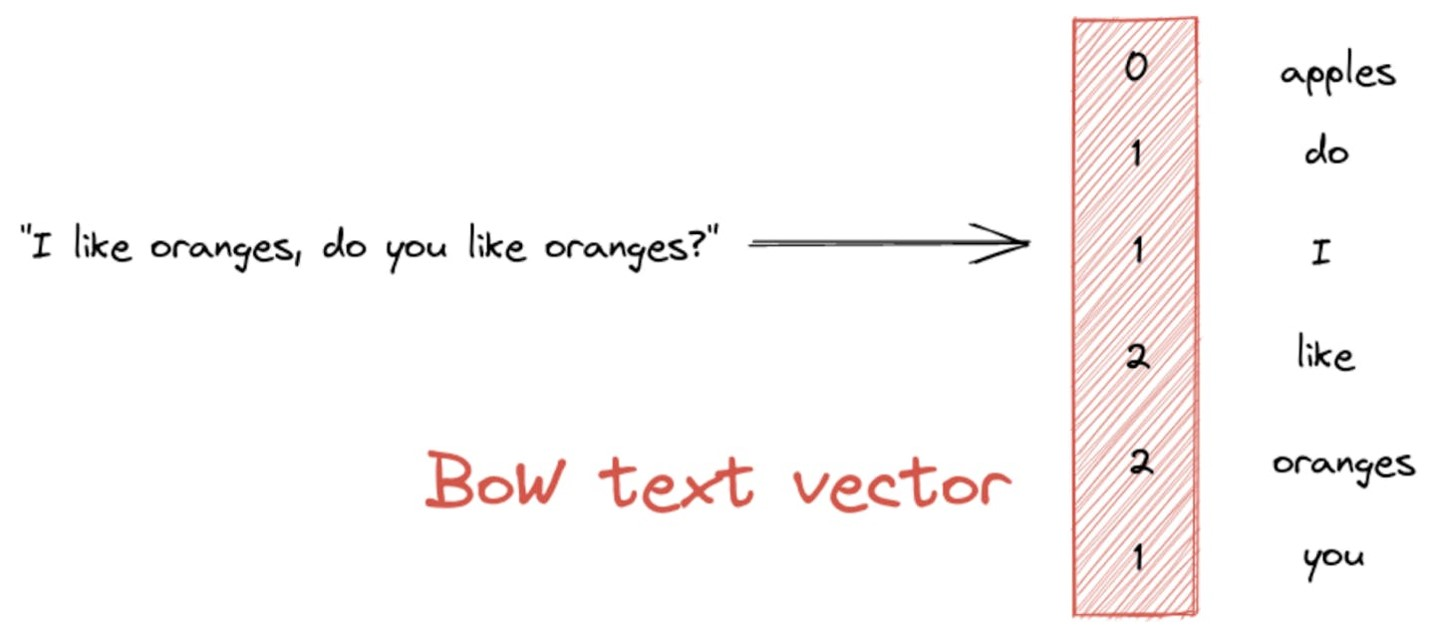



Однако на сегодняшнем занятии эта информация нам не понадобится :)

### 2. Рекуррентные нейросети (LSTM, внимание)



#### 2.1 Загрузка данных


В этом ноутбуке будем классифицировать тон комментариев. Данные хранятся на Kaggle (https://www.kaggle.com/datasets/abhi8923shriv/sentiment-analysis-dataset/data), но мы скачаем с диска.

In [23]:
!pip install gdown > /dev/null
!gdown https://drive.google.com/uc?id=1J5v1zIW_6Fa2qHGrYnNTGvOqTHkfqNRw
!unzip -n archive.zip > /dev/null

Downloading...
From (original): https://drive.google.com/uc?id=1J5v1zIW_6Fa2qHGrYnNTGvOqTHkfqNRw
From (redirected): https://drive.google.com/uc?id=1J5v1zIW_6Fa2qHGrYnNTGvOqTHkfqNRw&confirm=t&uuid=7311c747-f110-457a-991a-f7e46daa1567
To: /content/archive.zip
100% 57.1M/57.1M [00:01<00:00, 44.0MB/s]


In [24]:
df_train = pd.read_csv("train.csv", encoding='ISO-8859-1')
df_test = pd.read_csv("test.csv", encoding='ISO-8859-1')

df_train.head()

,textID,text,selected_text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral,morning,0-20,Afghanistan,38928346,652860.0,60
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative,noon,21-30,Albania,2877797,27400.0,105
2,088c60f138,my boss is bullying me...,bullying me,negative,night,31-45,Algeria,43851044,2381740.0,18
3,9642c003ef,what interview! leave me alone,leave me alone,negative,morning,46-60,Andorra,77265,470.0,164
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative,noon,60-70,Angola,32866272,1246700.0,26


Нам понадобятся колонки `text` и `sentiment`.

In [25]:
df_train = df_train[['text', 'sentiment']]
df_test = df_test[['text', 'sentiment']]

df_train.dropna(inplace=True)
df_test.dropna(inplace=True)

df_train['sentiment'].value_counts()

,count
sentiment,
neutral,11117
positive,8582
negative,7781


Пользуясь полученными выше знаниями, преобразуем текстовую колонку. При этом сохраним преобразованный текст в новую колонку, чтобы сравнить, как предобработка влияет на качество.

Давайте дополним код функции `tokenize`, руководствуясь комментариями.

In [26]:
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def tokenize(text):
    if not isinstance(text, str):
        return []
    # приведите текст к нижнему регистру
    text = text.lower()
    # удалите все небуквенные и непробельные символы
    text = re.sub(r'[^\sa-zа-я]','',text)
    # разбейте текст на токены и удалите стоп-слова. Результат верните в виде списка токенов.
    tokens = [i for i in text.split() if i not in stop_words]
    return tokens

df_train['text'] = df_train['text'].astype(str)
df_test['text'] = df_test['text'].astype(str)

df_train['clever_tokenized'] = df_train['text'].apply(tokenize)
df_test['clever_tokenized'] = df_test['text'].apply(tokenize)

df_train['simple_tokenized'] = df_train['text'].apply(lambda x: x.split())
df_test['simple_tokenized'] = df_test['text'].apply(lambda x: x.split())

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2096/2606107725.py:10: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub('[^\sa-zа-я]','',text)
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [27]:
tokenize(example + 'in')

['я', 'очень', 'люблю', 'курс', 'по', 'deep', 'learning', 'в', 'году']

In [28]:
df_train.head()

,text,sentiment,clever_tokenized,simple_tokenized
0,"I`d have responded, if I were going",neutral,"[id, responded, going]","[I`d, have, responded,, if, I, were, going]"
1,Sooo SAD I will miss you here in San Diego!!!,negative,"[sooo, sad, miss, san, diego]","[Sooo, SAD, I, will, miss, you, here, in, San,..."
2,my boss is bullying me...,negative,"[boss, bullying]","[my, boss, is, bullying, me...]"
3,what interview! leave me alone,negative,"[interview, leave, alone]","[what, interview!, leave, me, alone]"
4,"Sons of ****, why couldn`t they put them on t...",negative,"[sons, couldnt, put, releases, already, bought]","[Sons, of, ****,, why, couldn`t, they, put, th..."


Теперь мы можем создать словарь, с помощью которого будем численно кодировать токены из текста и наоборот. Чтобы создать такой словарь, сначала нужно создать словарь со всеми токенами в тексте и их частотами встречаемости:

In [29]:
counter_simple = defaultdict(int)

for i, raw in df_train.iterrows():
    for token in raw['simple_tokenized']:
        counter_simple[token] += 1

Для работы с текстами нам необходимо зарезервировать два специальных токена:

1. `<pad>` для токена означающего паддинг
1. `<unk>` для токенов, которые отсутствуют в словаре

In [30]:
specials = ['<pad>', '<unk>']
for special in specials:
    counter_simple[special] = 0

Теперь напишем функцию, которая создадет словарь, по токену выдающий число.

In [31]:
def make_dict(counter, specials, max_size=5000):
    """
    Создает словари индексации слов (stoi и itos) на основе частотного счетчика.

    Параметры:
    ----------
    counter : dict или collections.Counter
        Словарь, где ключ — слово, значение — его частота в тексте.
    specials : iterable
        Список специальных токенов (например, ['<pad>', '<unk>']),
        которые должны идти в начале словаря.
    max_size : int, optional
        Максимальный размер итогового словаря (по умолчанию 5000).

    Возвращает:
    -----------
    stoi : dict
        Словарь "слово -> индекс" (String-to-Index).
    itos : list
        Список "индекс -> слово" (Index-to-String).
    """
    # Инициализируем список слов специальными токенами (они займут первые индексы)
    itos = list(specials)

    # Создаем копию счетчика, чтобы не изменять оригинальные данные из параметров
    counter = counter.copy()

    # Удаляем специальные токены из счетчика частот,
    # чтобы они не участвовали в обычной сортировке по частоте
    for tok in specials:
        if tok in counter:  # Добавлена проверка на случай, если токена нет в counter
            del counter[tok]

    # Сортируем слова сначала по алфавиту (для стабильности сортировки),
    # а затем по частоте в убывающем порядке (чтобы самые частые шли первыми)
    words_and_frequencies = sorted(counter.items(), key=lambda tup: tup[0])
    words_and_frequencies.sort(key=lambda tup: tup[1], reverse=True)

    # Заполняем список itos отсортированными словами, пока не достигнем max_size
    for word, freq in words_and_frequencies:
        if len(itos) == max_size:
            break
        itos.append(word)

    # Создаем инвертированный словарь: отображение слова на его индекс в списке itos
    stoi = {tok: i for i, tok in enumerate(itos)}

    return stoi, itos

In [32]:
stoi, itos = make_dict(counter_simple, specials)
stoi['<pad>']

0

In [35]:
# stoi

In [33]:
stoi["<unk>"]

1

Также давайте реализуем функцию `lookup_indices`, которая по списку токенов возвращает список чисел.

Наконец мы готовы создать обёртку-датасет для наших данных.

Необходимо добавить несколько опции, которые понадобятся нам далее:

1. Ограничение на максимальную длину текста в токенах. Если текст оказывается длиннее, то последние токены отбрасываются.
2. Возможность добавить специальные токены <sos>, <eos> в начало и конец токенизированного текста.

In [36]:
import torch
from torch.utils.data import Dataset

class ReviewDataset(Dataset):
    """
    Кастомный датасет PyTorch для загрузки и предобработки текстовых отзывов.
    Преобразует токены в их числовые идентификаторы (ID), добавляет служебные
    токены начала (<sos>) и конца (<eos>) последовательности, а также кодирует метки настроения.
    """
    def __init__(self, data,
                 max_len,
                 stoi, itos,
                 token_column='simple_tokenized',
                 label_column='sentiment',
                 pad_sos=False, pad_eos=False):
        """
        :param pd.DataFrame data: Исходный датафрейм с текстами, токенами и метками.
        :param int max_len: Максимальная длина токенизированного текста (для обрезки).
        :param dict stoi: Словарь отображения "слово -> индекс".
        :param list itos: Список отображения "индекс -> слово".
        :param str token_column: Название колонки в data, содержащей списки токенов.
        :param str label_column: Название колонки в data, содержащей текстовые метки настроения.
        :param bool pad_sos: Если True, добавляет токен начала предложения <sos> в начало.
        :param bool pad_eos: Если True, добавляет токен конца предложения <eos> в конец.
        """
        super().__init__()

        # Создаем копии словарей, чтобы не изменять внешние объекты
        self.stoi = stoi.copy()
        self.itos = itos.copy()

        # Динамически регистрируем токен <sos> (Start of Sequence), если флаг равен True
        self.pad_sos = pad_sos
        if self.pad_sos:
            self.itos.append('<sos>')
            self.stoi['<sos>'] = len(self.itos) - 1 # Исправлено: индекс должен быть на 1 меньше длины списка
            self.sos_id = self.stoi['<sos>']

        # Динамически регистрируем токен <eos> (End of Sequence), если флаг равен True
        self.pad_eos = pad_eos
        if self.pad_eos:
            self.itos.append('<eos>')
            self.stoi['<eos>'] = len(self.itos) - 1 # Исправлено: индекс должен быть на 1 меньше длины списка
            self.eos_id = self.stoi['<eos>']

        self.max_len = max_len
        self.data = data.copy()

        # Инициализируем списки для хранения обработанных данных
        self.texts = []
        self.tokens = []
        self.ratings = []
        self.tokens_len = []

        # Маппим текстовые метки настроения в целочисленные классы (0, 1, 2) и конвертируем в PyTorch тензор
        # Внимание: в docstring __getitem__ указано "0 for negative, 1 for positive", проверьте соответствие логики ниже!
        self.labels = torch.tensor(data[label_column]
                                   .replace({'neutral': 0,
                                             'negative': 1,
                                             'positive': 2}),
                                   dtype=torch.long)

        # Итерируемся по строкам датафрейма для обработки каждого отзыва
        for i, row in data.iterrows():
            self.texts.append(row['text'])
            tokens = row[token_column]
            leng = 0
            my_tokens = []

            # Добавляем ID токена начала строки, если требуется
            if self.pad_sos:
                my_tokens.append(self.sos_id)

            # Ограничиваем длину токенов до max_len и переводим каждое слово в его ID
            for token in tokens[:self.max_len]:
                leng += 1
                my_tokens.append(self.lookup_indices([token])[0])

            # Добавляем ID токена конца строки, если требуется
            if self.pad_eos:
                my_tokens.append(self.eos_id)

            # Корректируем итоговую длину последовательности с учетом добавленных флагов <sos> / <eos>
            leng = min(leng, self.max_len)
            leng += int(self.pad_sos) # Преобразование bool в int (True -> 1, False -> 0)
            leng += int(self.pad_eos)

            # Сохраняем токены и их длину в виде тензоров PyTorch
            self.tokens.append(torch.tensor(my_tokens, dtype=torch.long))
            self.tokens_len.append(torch.tensor(leng, dtype=torch.long))

    def __getitem__(self, idx):
        """
        Возвращает один объект (семпл) из датасета по его индексу.

        :param int idx: Индекс объекта.
        :return dict: Словарь с тензорами и исходным текстом для модели:
            {
                'text': str (исходный необработанный текст),
                'label': torch.Tensor (ID класса настроения),
                'tokens': torch.Tensor (список ID токенов),
                'tokens_len': torch.Tensor (реальная длина текста)
            }
        """
        return {'text': self.texts[idx], 'label': self.labels[idx],
                'tokens': self.tokens[idx], 'tokens_len': self.tokens_len[idx]}

    def __len__(self):
        """
        Возвращает общее количество объектов в датасете.
        """
        return len(self.texts)

    def lookup_indices(self, text_list):
        """
        Конвертирует список строковых токенов в список соответствующих им ID.
        Если токена нет в словаре stoi, возвращает ID специального токена '<unk>'.

        :param list text_list: Список токенов (слов).
        :return list: Список целочисленных идентификаторов токенов.
        """
        return [self.stoi[text] if text in self.stoi else self.stoi['<unk>'] for text in text_list]


In [37]:
train_dataset = ReviewDataset(df_train, 200, stoi, itos)
test_dataset = ReviewDataset(df_test, 200, stoi, itos)

/tmp/ipykernel_2096/2245807323.py:58: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({'neutral': 0,


In [38]:
train_dataset[-1]

{'text': '   All this flirting going on - The ATG smiles. Yay.  ((hugs))',
 'label': tensor(0),
 'tokens': tensor([543,  30,   1,  43,  15,  35, 100,   1,   1,   1,   1]),
 'tokens_len': tensor(11)}

Посмотрим, как выглядит объект в датасете:

In [39]:
test_dataset[0]

{'text': 'Last session of the day  http://twitpic.com/67ezh',
 'label': tensor(0),
 'tokens': tensor([ 851, 1582,   13,    4,   34,    1]),
 'tokens_len': tensor(6)}

Теперь нам нужно создать `DataLoader` для наших данных. Мы уже знаем, что `DataLoader` умеет из коробки объединять список объектов из датасета в один батч, даже когда датасет возвращает словарь тензоров. Однако, это работает только в случае когда все эти тензоры имеют один и тот же размер во всех батчах. В нашем случае, это не так, так как разные тексты могут иметь разную длину.

Чтобы обойти эту проблему, у `DataLoader` зададим кастомную функцию `collate_fn`.

Чтобы объединить несколько тензоров разной длины в один можно использовать функцию `torch.nn.utils.rnn.pad_sequence`.

Обратите внимание на её аргументы:

1. `batch_first` определяет по какой оси "складывать" тензоры. Предпочтительнее использовать `batch_first=False`.
  - Если `batch_first=True`, то выходной тензор будет иметь форму `(batch_size, max_seq_length, *)`, где `batch_size` — это количество последовательностей в пакете, а `max_seq_length` — длина самой длинной последовательности после паддинга. Это означает, что первая размерность соответствует размеру пакета.

  - Если `batch_first=False` (что является значением по умолчанию), то выходной тензор будет иметь форму `(max_seq_length, batch_size, *)`. В этом случае первая размерность соответствует длине последовательности.
2. `padding_value` - число, которое будет использоваться в качестве паддинга, чтобы сделать все тензоры одинаковой длины

In [40]:
torch.nn.utils.rnn.pad_sequence([
    torch.tensor([1, 2, 3]),
    torch.tensor([4, 5]),
    torch.tensor([6, 7, 8, 9])
], batch_first=False, padding_value=0)

tensor([[1, 4, 6],
        [2, 5, 7],
        [3, 0, 8],
        [0, 0, 9]])

In [41]:
def collate_fn(batch, padding_value, batch_first=False):
    """
    Функция группировки (collate) для PyTorch DataLoader.
    Собирает отдельные элементы выборки в один батч, выравнивая последовательности
    токенов по максимальной длине в батче с помощью заполнения (padding).

    Параметры:
    ----------
    batch : list
        Список словарей, возвращаемых методом __getitem__ датасета ReviewDataset.
    padding_value : int
        ID токена паддинга (обычно индекс токена <pad>), которым будут заполняться пустые места.
    batch_first : bool, optional
        Если True, тензор токенов будет иметь форму [Batch_Size, Seq_Len].
        Если False (по умолчанию), форма будет [Seq_Len, Batch_Size], что стандартно для многих RNN.

    Возвращает:
    -----------
    dict
        Словарь, содержащий сгруппированные данные батча:
        - 'labels': тензор меток классов.
        - 'tokens': тензор выровненных по длине токенов.
        - 'tokens_lens': тензор исходных длин последовательностей.
        - 'texts': список оригинальных текстов.
    """
    # Инициализируем списки данными из самого первого элемента батча (индекс 0)
    labels = [batch[0]['label'].item()]
    texts = [batch[0]['text']]
    tokens = [batch[0]['tokens']]
    tokens_lens = [batch[0]['tokens_len'].item()]

    # Итерируемся по всем оставшимся элементам батча, начиная со второго
    for elem in batch[1:]:
        labels.append(elem['label'].item())       # Извлекаем числовое значение метки
        tokens.append(elem['tokens'])             # Добавляем тензор токенов (пока без выравнивания)
        tokens_lens.append(elem['tokens_len'].item()) # Извлекаем реальную длину текста
        texts.append(elem['text'])                # Добавляем сырой текст

    # Выравниваем последовательности токенов по длине самого длинного текста в текущем батче.
    # Короткие последовательности заполняются значением padding_value.
    tokens = torch.nn.utils.rnn.pad_sequence(tokens,
                                             padding_value=padding_value,
                                             batch_first=batch_first)

    # Возвращаем сформированный батч, превращая списки чисел в тензоры PyTorch
    return {'labels': torch.tensor(labels, dtype=torch.long),
            'tokens': tokens,
            'tokens_lens': torch.tensor(tokens_lens, dtype=torch.long),
            'texts': texts}


Наконец создадим даталоадеры.

In [44]:
from functools import partial

new_col = partial(collate_fn, padding_value=stoi['<pad>'], batch_first=False)

test_dataloader = DataLoader(test_dataset, batch_size=64,
                             collate_fn=new_col, shuffle=False, num_workers=0)
train_dataloader = DataLoader(train_dataset, batch_size=64,
                              collate_fn=new_col, shuffle=True, num_workers=0)

In [43]:
# new_col

Давайте посмотрим на какой-нибудь батч:

In [45]:
batch = next(iter(test_dataloader))
print(batch.keys())
print(f"labels: {batch['labels']}")
print(f"tokens: {batch['tokens']}")
print(f"tokens_lens: {batch['tokens_lens']}")

dict_keys(['labels', 'tokens', 'tokens_lens', 'texts'])
labels: tensor([0, 2, 1, 2, 2, 2, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 0,
        1, 2, 0, 0, 2, 1, 0, 0, 0, 0, 0, 2, 2, 0, 1, 1, 1, 0, 0, 0, 2, 2, 0, 2,
        1, 1, 0, 0, 1, 2, 0, 2, 0, 0, 0, 2, 0, 0, 0, 1])
tokens: tensor([[ 851,    1,    1,  ..., 4835,    1, 4693],
        [1582,   10,  484,  ..., 1870,   13, 3145],
        [  13,  318,    1,  ...,  425,    1,    9],
        ...,
        [   0,    0,    0,  ...,    0,    0,    0],
        [   0,    0,    0,  ...,    0,    0,    0],
        [   0,    0,    0,  ...,    0,    0,    0]])
tokens_lens: tensor([ 6, 15, 13,  2,  5,  4,  8, 13, 12, 18, 12,  5, 12, 25, 21, 18,  2,  4,
        13, 23,  7, 11,  8,  5,  7,  3, 21,  5,  9, 19, 12,  6, 24, 10,  3,  5,
         5, 21,  6, 13, 14, 12, 18, 20, 16,  7, 21,  4, 13,  2, 17,  7,  6,  2,
        14, 10, 25,  9, 19, 16,  9, 13, 13, 12])


In [ ]:
# batch['tokens'].shape

# batch['tokens']

torch.Size([25, 64])

#### 2.2 Vanilla RNN, LSTM, GRU

Рекуррентные нейронные сети (RNN, от англ. Recurrent Neural Networks) были разработаны для обработки и анализа последовательных данных, таких как временные ряды, текст, аудио и видео. В отличие от традиционных нейронных сетей, которые предполагают, что входные данные независимы друг от друга, RNN учитывают зависимость между элементами последовательности, что делает их особенно полезными для задач, где порядок и контекст имеют значение.

В таких задачах, как перевод или генерация текста, важно учитывать предыдущие слова или символы для правильного понимания и генерации следующего элемента. RNN способны сохранять информацию о предыдущих элементах последовательности через свои скрытые состояния.

**Vanilla RNN**

На каждом временном шаге $(t)$ RNN принимает входной вектор $( x_t )$ и предыдущее скрытое состояние $( h_{t-1} )$, чтобы вычислить новое скрытое состояние $( h_t )$. Это позволяет сети "помнить" информацию о предыдущих входах.

Обновление скрытого состояния происходит по следующей формуле:

$$h_t = \tanh(x_t W_{xh}^\top + h_{t-1}W_{hh}^\top + b_{h})$$

Здесь $( W_{xh} )$ — матрица весов для входного вектора, $( W_{hh} )$ — матрица весов для скрытого состояния, $( b_h )$ — вектор смещения, а $( \tanh )$ — активационная функция.

Выходной вектор $( y_t )$ на каждом временном шаге может быть вычислен как:

$$ y_t = h_t W_{hy}^T + b_y $$
Здесь $( W_{hy} )$ — матрица весов для преобразования скрытого состояния в выходной вектор, а $( b_y )$ — вектор смещения.

Несмотря на свои преимущества, классические RNN имеют некоторые ограничения, такие как проблемы с обучением на длинных последовательностях из-за затухающих или взрывающихся градиентов. Это привело к разработке более сложных архитектур, таких как LSTM (Long Short-Term Memory) и GRU (Gated Recurrent Unit), которые решают эти проблемы и улучшают способность сети запоминать долгосрочные зависимости.

![Три типа рекуррентных сетей](https://blog.kakaocdn.net/dn/dhSvks/btqGkfI4j9C/XHdlYGoUTDP8qGPIzDsLF1/img.png)

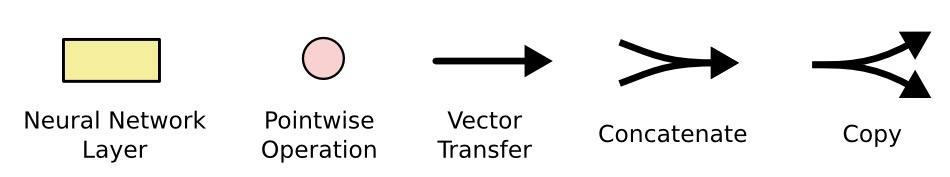

**LSTM (Long Short-Term Memory)** по сравнению с Vanilla RNN обладает несколькими ключевыми преимуществами: ячейка памяти (Cell State) и механизм врат (Gate) позволяют сохранять и извлекать информацию, когда это необходимо, что делает её более эффективной для задач с долгосрочными зависимостями.

1. Ячейка памяти (Cell State):
   - Это основная часть LSTM, которая отвечает за хранение информации. Ячейка памяти может сохранять информацию на протяжении длительных временных интервалов.

2. Входные врата (Input Gate):
   - Определяют, какая новая информация будет добавлена в ячейку памяти. Они состоят из сигмоидной функции активации, которая решает, какие значения обновлять, и тэнх-функции, которая генерирует новые кандидаты для добавления.

3. Забывающие врата (Forget Gate):
   - Определяют, какая информация из ячейки памяти будет удалена. Это позволяет LSTM забывать ненужную информацию, что помогает избежать затухания градиентов.

4. Выходные врата (Output Gate):
   - Определяют, какая информация из ячейки памяти будет использована для вычисления выходного значения на текущем временном шаге.

На каждом временном шаге $( t )$ LSTM обновляет свои состояния следующим образом:

1. Забывающие врата:
   $$f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$$
   Здесь $( \sigma )$ — сигмоидная функция активации, $( W_f )$ — матрица весов, $( b_f )$ — вектор смещения.

2. Входные врата:
   $$i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$$
   $$\tilde{C}_t = \tanh(W_C \cdot [h_{t-1}, x_t] + b_C)$$

3. Обновление состояния ячейки:
   $$C_t = f_t \cdot C_{t-1} + i_t \cdot \tilde{C}_t$$

4. Выходные врата:
   $$o_t = \sigma(W_o \cdot [h_{t-1}, x_t] + b_o)$$

5. Обновление скрытого состояния:
   $$h_t = o_t \cdot \tanh(C_t)$$

**GRU**

GRU имеет более простую архитектуру по сравнению с LSTM. Она объединяет забывающие и входные врата в одно "обновляющее врата" и не имеет отдельной ячейки памяти. Это упрощает модель и уменьшает количество параметров, что может привести к более быстрой и эффективной тренировке.

Из-за своей более простой структуры GRU имеет меньше параметров, чем LSTM. Это может быть преимуществом в условиях ограниченных вычислительных ресурсов или при работе с небольшими наборами данных, так как модель может быть менее подвержена переобучению.

GRU использует два основных типа врат: обновляющие и сбрасывающие.

1. Обновляющие врата (Update Gate):
   - Эти врата определяют, какая часть предыдущего скрытого состояния будет сохранена и перенесена в текущее состояние. Они помогают модели решать, какую информацию из прошлого состояния сохранить.

2. Сбрасывающие врата (Reset Gate):
   - Эти врата определяют, какая часть предыдущего скрытого состояния будет забыта. Это позволяет модели сбрасывать ненужную информацию и фокусироваться на новой входной информации.

На каждом временном шаге \( t \) GRU обновляет свои состояния следующим образом:

1. Обновляющие врата:
   $$z_t = \sigma(W_z \cdot [h_{t-1}, x_t] + b_z)$$
   Здесь $( \sigma )$ — сигмоидная функция активации, $( Wz )$ — матрица весов, $( b_z )$ — вектор смещения.

2. Сбрасывающие врата:
   $$r_t = \sigma(W_r \cdot [h_{t-1}, x_t] + b_r)$$

3. Кандидат на новое скрытое состояние:
   $$\tilde{h}_t = \tanh(W_h \cdot r_t \cdot [h_{t-1}, x_t] + b_h)$$

4. Обновление скрытого состояния:
   $$h_t = (1 - z_t) \cdot h_{t-1} + z_t \cdot \tilde{h}_t$$

В библиотеке Pytorch RNN реализована при помощи модуля `nn.RNN`. Однако на вход в этот блок приходит числовой вектор. Давайте посмотрим, как изнутри выглядит проход по последовательности RNN.

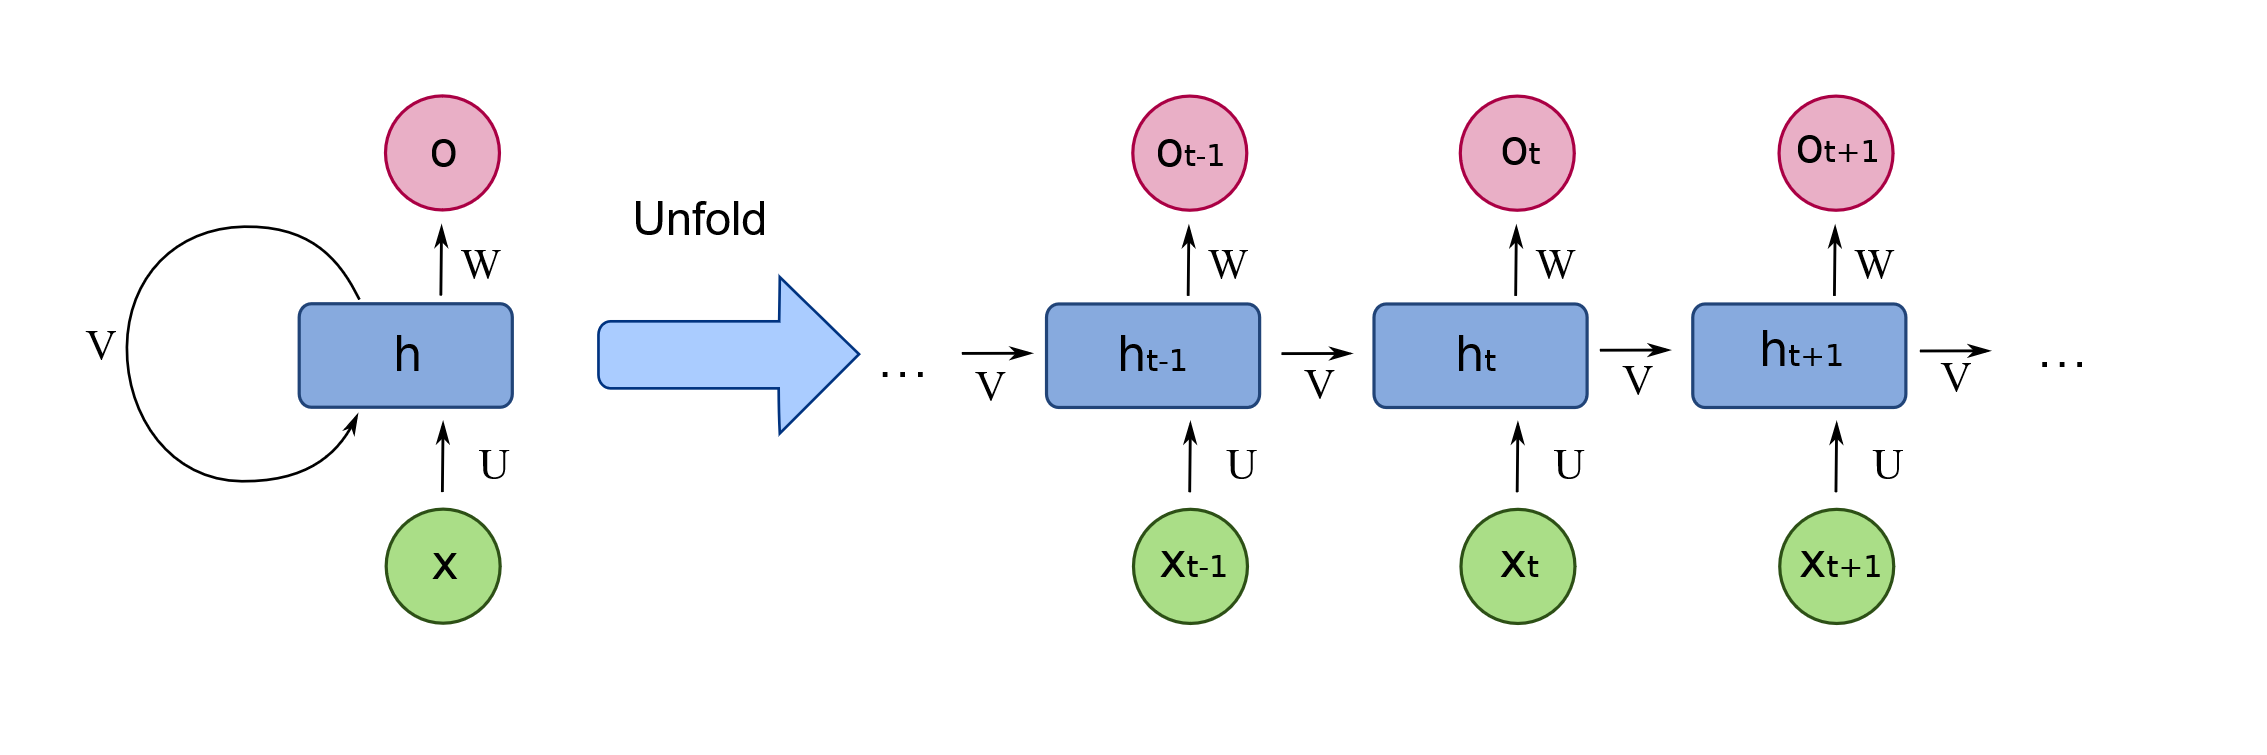

Задаем нужные параметры.

In [46]:
input_size = 3  # Размер входного вектора
hidden_size = 5  # Размер скрытого слоя
output_size = 2  # Размер выходного вектора
sequence_length = 4  # Длина последовательности
batch_size = 1  # Размер батча

Создадим RNN-ячейку.

In [55]:
rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size, batch_first=True)
fc = nn.Linear(hidden_size, output_size)

Создадим случайный вектор, на котором будем экспериментировать.

In [56]:
inputs = torch.randn(batch_size, sequence_length, input_size)

Для работы RNN необходимо инициализировать скрытое состояние.

In [57]:
h = torch.zeros(inputs.size(0), inputs.size(1), hidden_size)  # Инициализация скрытого состояния
out, h = rnn(inputs)  # Выполняем проход по элементам
output = fc(out)  # Формируем выходной вектор

In [58]:
print(output, output.shape) # batch_size, seq_len, output_size
print('------------')
print(h, h.shape) # batch_size, num_layers, hidden_size

tensor([[[-0.2588,  0.2270],
         [-0.2749,  0.1237],
         [-0.2128,  0.2089],
         [ 0.1462,  0.3801]]], grad_fn=<ViewBackward0>) torch.Size([1, 4, 2])
------------
tensor([[[ 0.0924, -0.7057,  0.0457, -0.8809,  0.2005]]],
       grad_fn=<StackBackward0>) torch.Size([1, 1, 5])


Теперь давайте обсудим, как работать с самим текстом. Для преобразования токенов в эмбеддинги в `torch` существует модуль `nn.Embedding`. Он принимает в качестве параметров:
   - `num_embeddings`: количество уникальных токенов (размер словаря).
   - `embedding_dim`: размерность векторного представления каждого токена.

In [62]:
  embedding = nn.Embedding(num_embeddings=len(stoi), embedding_dim=32, padding_idx=0)

In [63]:
print(batch['tokens'][:1].shape)

torch.Size([1, 64])


Для каждого входного индекса модуль возвращает соответствующий вектор из матрицы эмбеддингов. Выходной тензор имеет размерность, соответствующую входному тензору, но с добавленной размерностью для векторного представления.

В начале матрица эмбеддингов инициализируется случайными значениями. В процессе тренировки модели она обучается через обратное распространение ошибки. Каждый вектор в этой матрице соответствует одному токену.

In [64]:
len(batch['tokens'][:1][0])

64

In [65]:
emb = embedding(batch['tokens'])
print(emb.shape)
print(emb)

torch.Size([25, 64, 32])
tensor([[[-0.3089, -0.7694, -0.5359,  ..., -1.9828, -1.3832,  0.1289],
         [ 0.8358,  0.4279, -0.7372,  ...,  0.1617, -1.0827, -2.1740],
         [ 0.8358,  0.4279, -0.7372,  ...,  0.1617, -1.0827, -2.1740],
         ...,
         [-0.0654, -2.1476, -0.2796,  ...,  0.4811,  0.7835,  1.9719],
         [ 0.8358,  0.4279, -0.7372,  ...,  0.1617, -1.0827, -2.1740],
         [ 1.9355, -1.0893, -1.6012,  ...,  2.3488,  0.0939, -0.4982]],

        [[ 1.3418, -1.5339,  0.6218,  ..., -0.4621,  0.2878, -0.0356],
         [-0.5445,  0.9355,  0.0460,  ..., -0.8384,  0.7692,  1.3727],
         [-1.0880,  0.4156, -0.1522,  ...,  0.7988,  0.2685,  1.1004],
         ...,
         [ 1.1590, -0.1642,  0.9985,  ...,  0.4814, -0.1834,  0.4895],
         [-1.2646,  0.3560, -0.1382,  ..., -1.2496, -0.5570, -1.3857],
         [-1.7941,  1.7842,  1.0239,  ..., -0.0665, -0.4988,  0.0854]],

        [[-1.2646,  0.3560, -0.1382,  ..., -1.2496, -0.5570, -1.3857],
         [ 1.3457,  

Наша нейросеть будет обрабатывать входную последовательность по словам (word level). Мы будем использовать простую и стандартную рекуррентную архитектуру для классификации:

1. Слой представлений, превращающий id токена в вектор-ембеддинг этого слова
2. Слой RNN
3. Полносвязный слой, предсказывающий выход по последнему скрытому состоянию

In [66]:
class RNNClassifier(nn.Module):
    """
    Классификатор текстов на основе рекуррентной нейронной сети (RNN/LSTM/GRU).
    Принимает токены, переводит их в эмбеддинги, прогоняет через RNN-слой
    и классифицирует на основе скрытого состояния последнего валидного токена.
    """
    def __init__(self, embedding_dim, hidden_size, output_size, vocab,
                 rec_layer=nn.RNN):
        """
        :param int embedding_dim: Размерность векторного представления слова (эмбеддинга).
        :param int hidden_size: Количество нейронов в скрытом слое RNN.
        :param int output_size: Количество классов для предсказания (например, 3 для sentiment).
        :param dict/Vocab vocab: Словарь или объект вокабуляра для определения размера словаря.
        :param nn.Module rec_layer: Тип рекуррентного слоя (nn.RNN, nn.GRU или nn.LSTM).
        """
        super(RNNClassifier, self).__init__()
        self.vocab = vocab
        self.hidden_size = hidden_size
        self.embedding_dim = embedding_dim

        # Слой эмбеддингов: переводит ID токенов в плотные векторы.
        # padding_idx=0 указывает, что токен с ID=0 (обычно <pad>) инициализируется нулями и не обучается.
        self.word_embeddings = nn.Embedding(len(self.vocab), self.embedding_dim, padding_idx=0)

        # Рекуррентный слой (по умолчанию nn.RNN). Работает в формате [seq_len, batch_size, embedding_dim]
        self.rnn_cell = rec_layer(self.embedding_dim, self.hidden_size)

        # Полносвязный (линейный) слой для отображения скрытого состояния сети в логиты классов
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, tokens, tokens_lens):
        """
        Прямой проход модели.

        :param torch.Tensor tokens: Тензор с ID токенов формы [seq_len, batch_size].
        :param torch.Tensor tokens_lens: Тензор с реальными длинами текстов формы [batch_size].
        :return torch.Tensor: Логиты предсказаний классов формы [batch_size, output_size].
        """
        # Переводим токены в эмбеддинги.
        # Форма на выходе: [seq_len, batch_size, embedding_dim]
        embeddings = self.word_embeddings(tokens)

        # Прогон через рекуррентную сеть.
        # rnn_output содержит скрытые состояния для ВСЕХ временных шагов (токенов).
        # Форма rnn_output: [seq_len, batch_size, hidden_size]
        rnn_output, hidden = self.rnn_cell(embeddings)

        # Так как тексты в батче дополнены паддингом (<pad>) до максимальной длины,
        # нам нужно взять скрытое состояние сети СРАЗУ ПОСЛЕ реального последнего слова отзыва.

        # Создаем вектор индексов батча: [0, 1, 2, ..., batch_size - 1]
        # embeddings.shape[1] — это как раз batch_size.
        idx = torch.arange(embeddings.shape[1])

        # Магия индексации PyTorch:
        # 1. tokens_lens - 1 определяет индекс последнего реального токена для каждого текста.
        # 2. idx сопоставляет этот токен с правильным элементом в батче.
        # Вырезаем тензор формы [batch_size, hidden_size].
        last_valid_outputs = rnn_output[tokens_lens - 1, idx, :]

        # Передаем скрытые состояния последних токенов в полносвязный слой
        return self.fc(last_valid_outputs)


In [67]:
if torch.cuda.is_available():
    device = 'cuda'
else:
    device = torch.device('cpu')
print(f'Using device: {device}')

Using device: cuda


Создадим модель на основе RNN:

In [68]:
model_rnn = RNNClassifier(
            embedding_dim=32, hidden_size=128, output_size=3, vocab=stoi,
).to(device)

In [69]:
# 2. Имитируем входные данные: батч токенов в формате [seq_len, batch_size]
# (Поскольку collate_fn выдает batch_first=False, seq_len идет первой!)
tokens = torch.randint(low=0, high=len(stoi), size=(sequence_length, batch_size)).to(device)

# 3. Имитируем реальные длины текстов (значения от 1 до sequence_length)
# Тензор должен иметь форму [batch_size]
tokens_lens = torch.randint(low=1, high=sequence_length + 1, size=(batch_size,)).to(device)

In [70]:
model_rnn(tokens, tokens_lens)

tensor([[ 0.0684,  0.0776, -0.0067]], device='cuda:0',
       grad_fn=<AddmmBackward0>)

In [ ]:
h.shape

torch.Size([1, 1, 5])

In [71]:
def train_epoch(dataloader, model, loss_fn, optimizer, device, max_grad_norm=1.0):
    """
    Обучает модель в течение одной эпохи.

    Параметры:
    ----------
    max_grad_norm : float
        Максимальный порог для нормы градиентов (используется для клипирования).
    """
    # Переводим модель в режим обучения (активируются Dropout, BatchNorm и т.д.)
    model.train()

    for idx, data in enumerate(dataloader):
        # 1. Извлекаем данные из батча и переносим их на целевое устройство (GPU/CPU)
        tokens = data['tokens'].to(device)
        tokens_lens = data['tokens_lens'].to(device)
        labels = data['labels'].to(device)

        # Обнуляем сохраненные градиенты параметров с предыдущего шага
        optimizer.zero_grad()

        # 2. Прямой проход (Forward pass): получаем логиты предсказаний модели
        outputs = model(tokens, tokens_lens)

        # 3. Вычисляем значение функции потерь (Loss)
        loss = loss_fn(outputs, labels)

        # Обратный проход (Backward pass): считаем градиенты для всех параметров модели
        loss.backward()

        # Ограничиваем норму градиентов, чтобы избежать их «взрыва» в RNN-слоях
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)

        # 4. Обновляем веса модели на основе посчитанных и обрезанных градиентов
        optimizer.step()

def evaluate(dataloader, model, loss_fn, device):
    """
    Оценивает качество работы модели на валидационном или тестовом датасете.

    Возвращает:
    -----------
    float, float : средние потери и средний accuracy по всему датасету.
    """
    # Переводим модель в режим оценки (выключаются Dropout, BatchNorm и т.д.)
    model.eval()

    total_loss = 0.0
    total_accuracy = 0.0

    # Отключаем расчет градиентов для ускорения вычислений и экономии памяти
    with torch.no_grad():
        for idx, data in enumerate(dataloader):
            # 1. Извлекаем данные из батча и отправляем на устройство
            tokens = data['tokens'].to(device)
            tokens_lens = data['tokens_lens'].to(device)
            labels = data['labels'].to(device) # Изменено: считаем loss на device

            # 2. Прямой проход (Forward pass)
            outputs = model(tokens, tokens_lens)

            # 3. Вычисляем функцию потерь и суммируем её значение (.item() извлекает число из тензора)
            total_loss += loss_fn(outputs, labels).item()

            # 4. Вычисляем количество правильных ответов
            # torch.argmax(outputs, dim=1) находит индекс самого вероятного класса
            preds = torch.argmax(outputs, dim=1)
            total_accuracy += float(torch.sum(preds == labels))

    # Считаем средние значения (делим общую сумму на количество объектов в выборке)
    # Внимание: для total_loss здесь используется len(dataloader),
    # если loss_fn по умолчанию усредняет значения внутри батча (reduction='mean')
    avg_loss = total_loss / len(dataloader)
    avg_accuracy = total_accuracy / len(dataloader.dataset)

    return avg_loss, avg_accuracy


def train(
    train_loader, test_loader, model, loss_fn, optimizer, device, num_epochs, max_grad_norm=1.0
):
    """
    Основной цикл обучения модели на протяжении заданного количества эпох.
    """
    test_losses = []
    train_losses = []
    test_accuracies = []
    train_accuracies = []
    time_it = []

    for epoch in range(num_epochs):
        # Засекаем время начала текущей эпохи
        start = time.time()

        # Проводим одну эпоху обучения
        train_epoch(train_loader, model, loss_fn, optimizer, device, max_grad_norm)

        # Оцениваем метрики на обучающей выборке
        train_loss, train_acc = evaluate(train_loader, model, loss_fn, device)
        train_accuracies.append(train_acc)
        train_losses.append(train_loss)

        # Оцениваем метрики на тестовой выборке
        test_loss, test_acc = evaluate(test_loader, model, loss_fn, device)
        test_accuracies.append(test_acc)
        test_losses.append(test_loss)

        # Считаем время, затраченное на эпоху
        time_it.append(time.time() - start)

        # Выводим подробный лог состояния обучения
        print(
            'Epoch: {0:d}/{1:d}. Loss (Train/Test): {2:.3f}/{3:.3f}. Accuracy (Train/Test): {4:.3f}/{5:.3f}'.format(
                epoch + 1, num_epochs, train_losses[-1], test_losses[-1], train_accuracies[-1], test_accuracies[-1]
            )
        )

    return train_losses, train_accuracies, test_losses, test_accuracies, time_it


Создадим функцию потерь и оптимизатор:

In [72]:
loss_fn = torch.nn.CrossEntropyLoss(reduction='mean')
optimizer = torch.optim.Adam(model_rnn.parameters(), lr=0.01)

Обучим модель:

In [73]:
train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_rnn, loss_fn, optimizer, device, 10
)

Epoch: 1/10. Loss (Train/Test): 1.138/1.155. Accuracy (Train/Test): 0.313/0.298
Epoch: 2/10. Loss (Train/Test): 1.150/1.154. Accuracy (Train/Test): 0.371/0.372
Epoch: 3/10. Loss (Train/Test): 1.094/1.132. Accuracy (Train/Test): 0.395/0.369
Epoch: 4/10. Loss (Train/Test): 1.041/1.095. Accuracy (Train/Test): 0.472/0.437
Epoch: 5/10. Loss (Train/Test): 1.034/1.114. Accuracy (Train/Test): 0.508/0.466
Epoch: 6/10. Loss (Train/Test): 0.984/1.056. Accuracy (Train/Test): 0.524/0.486
Epoch: 7/10. Loss (Train/Test): 0.996/1.059. Accuracy (Train/Test): 0.512/0.454
Epoch: 8/10. Loss (Train/Test): 1.004/1.068. Accuracy (Train/Test): 0.504/0.449
Epoch: 9/10. Loss (Train/Test): 1.024/1.085. Accuracy (Train/Test): 0.483/0.439
Epoch: 10/10. Loss (Train/Test): 1.015/1.075. Accuracy (Train/Test): 0.491/0.442


Теперь давайте возьмем более продвинутую LSTM.

In [75]:
model_lstm = RNNClassifier(
    embedding_dim=32, hidden_size=128, output_size=3, vocab=stoi,
    rec_layer=nn.LSTM
).to(device)

loss_fn = nn.CrossEntropyLoss(reduction='mean')
optimizer = torch.optim.Adam(model_lstm.parameters(), lr=0.01)

In [76]:
train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_lstm, loss_fn, optimizer, device, 5
)

Epoch: 1/5. Loss (Train/Test): 0.733/0.799. Accuracy (Train/Test): 0.688/0.648
Epoch: 2/5. Loss (Train/Test): 0.575/0.735. Accuracy (Train/Test): 0.772/0.689
Epoch: 3/5. Loss (Train/Test): 0.481/0.746. Accuracy (Train/Test): 0.818/0.684
Epoch: 4/5. Loss (Train/Test): 0.399/0.789. Accuracy (Train/Test): 0.853/0.669
Epoch: 5/5. Loss (Train/Test): 0.326/0.874. Accuracy (Train/Test): 0.883/0.667


И еще ради интереса запустим `GRU`.

In [77]:
model_gru = RNNClassifier(
    embedding_dim=32, hidden_size=128, output_size=3, vocab=stoi,
    rec_layer=nn.GRU
).to(device)

loss_fn = nn.CrossEntropyLoss(reduction='mean')
optimizer = torch.optim.Adam(model_gru.parameters(), lr=0.01)

In [78]:
train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_gru, loss_fn, optimizer, device, 5
)

Epoch: 1/5. Loss (Train/Test): 0.694/0.770. Accuracy (Train/Test): 0.703/0.654
Epoch: 2/5. Loss (Train/Test): 0.588/0.734. Accuracy (Train/Test): 0.764/0.681
Epoch: 3/5. Loss (Train/Test): 0.521/0.764. Accuracy (Train/Test): 0.795/0.675
Epoch: 4/5. Loss (Train/Test): 0.500/0.791. Accuracy (Train/Test): 0.800/0.675
Epoch: 5/5. Loss (Train/Test): 0.520/0.805. Accuracy (Train/Test): 0.793/0.670


Давайте посмотрим на качество, которое у нас получилось.

In [79]:
def return_outputs(model, dataloader):
    model.eval()

    labels_all = []
    outputs_all = []
    with torch.no_grad():
        for idx, data in enumerate(dataloader):
            tokens, tokens_lens = data['tokens'].to(device), data['tokens_lens'].to(device)
            labels = data['labels']
            labels_all.extend(labels)
            outputs = model(tokens, tokens_lens).to('cpu')
            outputs_all.extend(outputs)
    return torch.concat([l.reshape(1) for l in labels_all]), torch.vstack(outputs_all)

Мы не перемешивали тест-датасет, поэтому можем использовать одни и те же лейблы.

In [80]:
labels, outputs_rnn = return_outputs(model_rnn, test_dataloader)
_, outputs_lstm = return_outputs(model_lstm, test_dataloader)
_, outputs_gru = return_outputs(model_gru, test_dataloader)

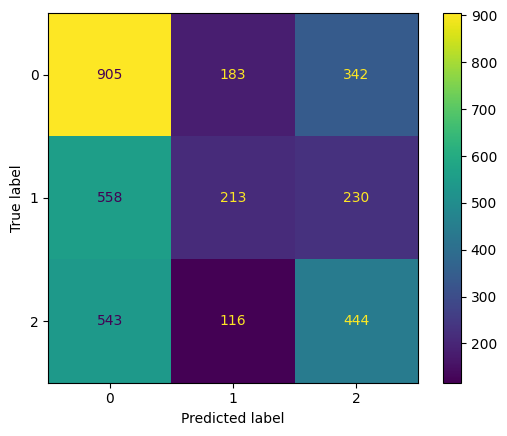

In [81]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(labels, torch.argmax(outputs_rnn, dim=1), labels=np.unique(labels))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

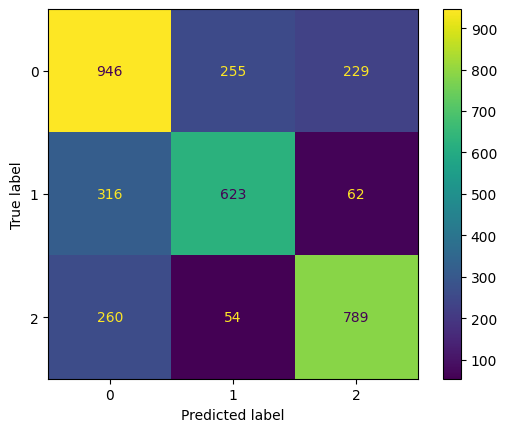

In [82]:
cm = confusion_matrix(labels, torch.argmax(outputs_lstm, dim=1), labels=np.unique(labels))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

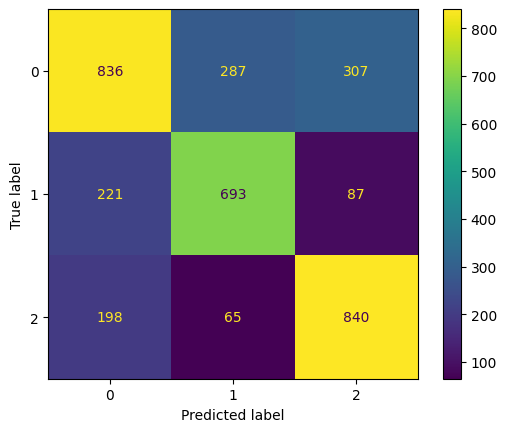

In [83]:
cm = confusion_matrix(labels, torch.argmax(outputs_gru, dim=1), labels=np.unique(labels))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

In [84]:
from sklearn.metrics import f1_score

print(f"RNN result: {f1_score(labels, torch.argmax(outputs_rnn, dim=1), average='macro')}")
print(f"LSTM result: {f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro')}")
print(f"GRU result: {f1_score(labels, torch.argmax(outputs_gru, dim=1), average='macro')}")

RNN result: 0.4091335773522052
LSTM result: 0.669457918795109
GRU result: 0.6730028365435271


Возможно, требуется более точная настройка моделей, но результаты по LSTM и GRU значительно лучше.

#### 2.3 То же самое с предобработкой :)

Создадим словарь предобработанных токенов:

In [85]:
counter_clever = defaultdict(int)

for i, raw in df_train.iterrows():
    for token in raw['clever_tokenized']:
        counter_clever[token] += 1

specials = ['<pad>', '<unk>']
for special in specials:
    counter_clever[special] = 0

stoi, itos = make_dict(counter_clever, specials)

Создадим соответствующие датасеты и даталоадеры:

In [86]:
train_dataset = ReviewDataset(df_train, 200, stoi, itos, token_column='clever_tokenized')
test_dataset = ReviewDataset(df_test, 200, stoi, itos, token_column='clever_tokenized')

test_dataloader = DataLoader(test_dataset, batch_size=64,
                             collate_fn=new_col, shuffle=False, num_workers=0)
train_dataloader = DataLoader(train_dataset, batch_size=64,
                              collate_fn=new_col, shuffle=True, num_workers=0)

/tmp/ipykernel_2096/2245807323.py:58: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({'neutral': 0,


И теперь будем запускать модельки :)

In [87]:
model_rnn_clever = RNNClassifier(
    embedding_dim=32, hidden_size=128, output_size=3, vocab=stoi
).to(device)

loss_fn = nn.CrossEntropyLoss(reduction='mean')
optimizer = torch.optim.Adam(model_rnn_clever.parameters(), lr=0.01)

train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_rnn_clever, loss_fn, optimizer, device, 5
)

Epoch: 1/5. Loss (Train/Test): 0.988/1.007. Accuracy (Train/Test): 0.519/0.515
Epoch: 2/5. Loss (Train/Test): 0.776/0.828. Accuracy (Train/Test): 0.665/0.624
Epoch: 3/5. Loss (Train/Test): 0.778/0.872. Accuracy (Train/Test): 0.659/0.611
Epoch: 4/5. Loss (Train/Test): 0.726/0.830. Accuracy (Train/Test): 0.686/0.643
Epoch: 5/5. Loss (Train/Test): 0.745/0.856. Accuracy (Train/Test): 0.685/0.624


In [88]:
model_lstm_clever = RNNClassifier(
    embedding_dim=32, hidden_size=128, output_size=3, vocab=stoi,
    rec_layer=nn.LSTM
).to(device)

loss_fn = nn.CrossEntropyLoss(reduction='mean')
optimizer = torch.optim.Adam(model_lstm_clever.parameters(), lr=0.01)

train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_lstm_clever, loss_fn, optimizer, device, 5
)

Epoch: 1/5. Loss (Train/Test): 0.652/0.719. Accuracy (Train/Test): 0.735/0.694
Epoch: 2/5. Loss (Train/Test): 0.516/0.696. Accuracy (Train/Test): 0.801/0.709
Epoch: 3/5. Loss (Train/Test): 0.425/0.725. Accuracy (Train/Test): 0.845/0.697
Epoch: 4/5. Loss (Train/Test): 0.335/0.803. Accuracy (Train/Test): 0.877/0.692
Epoch: 5/5. Loss (Train/Test): 0.263/0.885. Accuracy (Train/Test): 0.909/0.692


In [89]:
model_gru_clever = RNNClassifier(
    embedding_dim=32, hidden_size=128, output_size=3, vocab=stoi,
    rec_layer=nn.GRU
).to(device)

loss_fn = nn.CrossEntropyLoss(reduction='mean')
optimizer = torch.optim.Adam(model_gru_clever.parameters(), lr=0.01)

train_losses_pure, train_accuracies_pure, test_losses_pure, test_accuracies_pure, time_it_pure = train(
    train_dataloader, test_dataloader, model_gru_clever, loss_fn, optimizer, device, 5
)

Epoch: 1/5. Loss (Train/Test): 0.630/0.700. Accuracy (Train/Test): 0.746/0.713
Epoch: 2/5. Loss (Train/Test): 0.536/0.707. Accuracy (Train/Test): 0.791/0.703
Epoch: 3/5. Loss (Train/Test): 0.477/0.726. Accuracy (Train/Test): 0.820/0.691
Epoch: 4/5. Loss (Train/Test): 0.438/0.778. Accuracy (Train/Test): 0.837/0.685
Epoch: 5/5. Loss (Train/Test): 0.410/0.809. Accuracy (Train/Test): 0.845/0.684


Теперь также проверим качество.

In [90]:
labels, outputs_rnn = return_outputs(model_rnn_clever, test_dataloader)
_, outputs_lstm = return_outputs(model_lstm_clever, test_dataloader)
_, outputs_gru = return_outputs(model_gru_clever, test_dataloader)

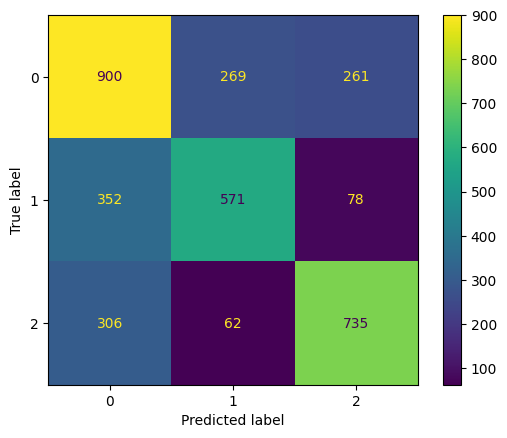

In [91]:
cm = confusion_matrix(labels, torch.argmax(outputs_rnn, dim=1), labels=np.unique(labels))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

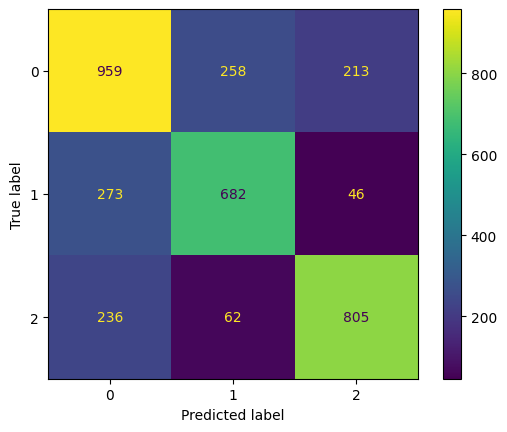

In [92]:
cm = confusion_matrix(labels, torch.argmax(outputs_lstm, dim=1), labels=np.unique(labels))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

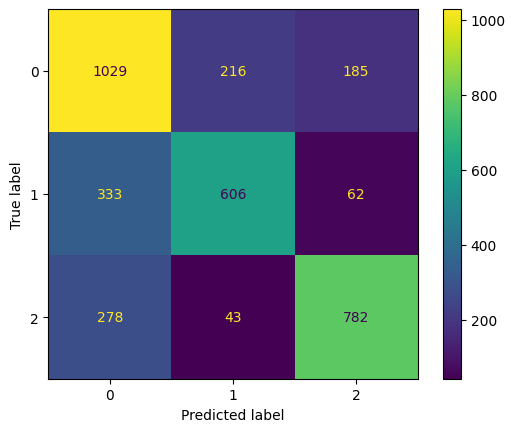

In [93]:
cm = confusion_matrix(labels, torch.argmax(outputs_gru, dim=1), labels=np.unique(labels))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=np.unique(labels))
disp.plot()
plt.show()

In [94]:
print(f"RNN result: {f1_score(labels, torch.argmax(outputs_rnn, dim=1), average='macro')}")
print(f"LSTM result: {f1_score(labels, torch.argmax(outputs_lstm, dim=1), average='macro')}")
print(f"GRU result: {f1_score(labels, torch.argmax(outputs_gru, dim=1), average='macro')}")

RNN result: 0.6259186311084702
LSTM result: 0.6952589673763927
GRU result: 0.6844864935858119


Предобработка позволила повысить качество для RNN! Для LSTM и GRU тоже, но не так значительно :)